# 03 — Conventional energy resolution: fixed-energy beams & Crystal-Ball fits

Notebooks 01–02 reduced every shower to a handful of per-event readouts. This notebook
turns those readouts into the standard calorimeter deliverable — the **energy resolution**
σ_E/E as a function of energy — the conventional way, the method calorimeter groups have
used at test beams for decades:

1. Simulate photons at a **handful of fixed energies** — a mono-energetic "beam" at each
   point, not a spectrum.
2. At each energy, histogram the detector response and **fit a Crystal-Ball function**
   (a Gaussian core with a low-side power-law tail).
3. Quote the **Gaussian-core width σ** as the resolution at that energy.
4. **Invert the calibration** (the peak readout against energy) to turn that width into an energy resolution σ_E/E, and plot
   it against energy — then confront it with the textbook
   $\sigma_E/E = a/\sqrt{E}\oplus b\oplus c/E$. Here $a\oplus b=\sqrt{a^2+b^2}$ (a sum in
   quadrature), and $a$, $b$, $c$ are the stochastic, constant and noise terms.

Everything here is deliberately transparent: no training, no black box — just a fit and a
curve you can read by eye. It is the **ground truth** for this detector. A second,
completely independent measurement of the same quantity — an ML density model trained on
the continuous spectrum — follows in
[`04_resolution_ml_crystalball.ipynb`](04_resolution_ml_crystalball.ipynb); where the two
agree, both are validated, and where they disagree, that is physics (saturation,
non-Gaussian tails), not a bug.

**Kernel**: `Key4hep (CPU)`.
**Input**: per-energy extracted observables in `models/mono_<particle>/` — one `.npz` per
fixed-energy run, spanning **1–400 GeV**. Generate the beams in
[`00_simulate_your_samples.ipynb`](00_simulate_your_samples.ipynb) (a fixed
`CALOMAPS_GUN_ENERGY_GEV` per energy), then extract the four readouts per energy with
`analysis/extract_readouts.py` — the batch/per-energy form of the
[`02_data_extraction.ipynb`](02_data_extraction.ipynb) readouts; its docstring has the exact
loop. (nb02 itself writes a *single* spectrum file, so it can't produce these per-energy
inputs directly.)
**Output**: the calibration, inversion, and resolution figures below.


**Where this notebook sits.** It measures the energy resolution from the four readouts of notebook 02, with fixed-energy runs; notebook 04 measures the same from the spectrum.

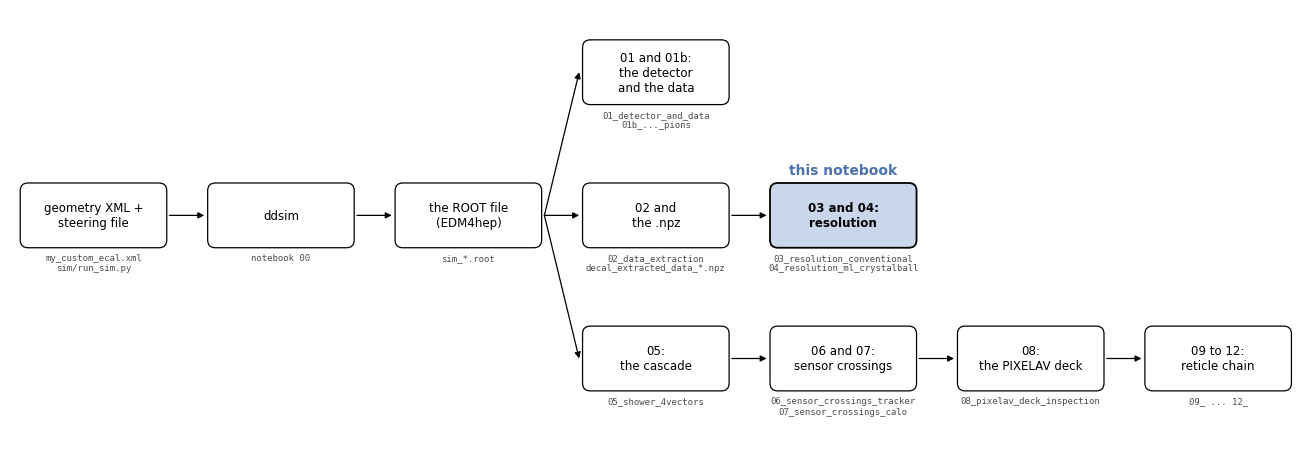

In [1]:
import os, sys
import matplotlib.pyplot as plt
_root = os.path.abspath(os.getcwd())     # the repository: the first folder up from here with analysis/pixelav
while not os.path.isdir(os.path.join(_root, "analysis", "pixelav")) and _root != os.path.dirname(_root):
    _root = os.path.dirname(_root)
sys.path.insert(0, os.path.join(_root, "analysis", "pixelav"))
import sketches                  # drawn schematics, no data (analysis/pixelav/sketches.py)

sketches.series_chain('03')
plt.show()

## 0. Choose your particle

The **one cell you change**. Everything downstream — which per-energy dataset directory is
read — derives from `PARTICLE`. Run it for photons and for pions and compare: hadronic
showers are broader and leak more, so expect a worse resolution and a larger constant term.

In [2]:
# ---- THE ONE KNOB ----
PARTICLE = "gamma"          # "gamma" or "pi+"
PART_TAG = "gamma" if PARTICLE == "gamma" else "piplus"
print(f"PARTICLE = {PARTICLE!r}  ->  reading models/mono_{PART_TAG}/")

PARTICLE = 'gamma'  ->  reading models/mono_gamma/


## 1. Setup

Repo-root self-location (works from a GUI kernel, which does not inherit a sourced
terminal's environment), the shared readout palette (matches `analysis/dashboard.py`), and
the per-energy data directory. Point `CALOMAPS_MONO_DIR` elsewhere if your fixed-energy
`.npz` live outside `models/`.

In [3]:
import os, glob, sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import crystalball, norm
from scipy.optimize import curve_fit

def _calomaps_home():
    h = os.environ.get("CALOMAPS_HOME")
    if h and os.path.isdir(os.path.join(h, "geometry")):
        return h
    p = os.path.abspath(os.getcwd())
    while p != os.path.dirname(p):
        if os.path.isdir(os.path.join(p, "geometry")) and os.path.isdir(os.path.join(p, "sim")):
            return p
        p = os.path.dirname(p)
    return os.path.expanduser("~/CALOMAPS")
CALOMAPS_HOME = _calomaps_home()
sys.path.insert(0, os.path.join(CALOMAPS_HOME, "analysis"))
from decal_cbfit import fit_response, build_calibration    # shared estimator (also used by notebook 04)
MONO_DIR = os.environ.get("CALOMAPS_MONO_DIR",
                          os.path.join(CALOMAPS_HOME, "models", f"mono_{PART_TAG}"))

# four readouts, increasing digitization (palette matches analysis/dashboard.py)
KEYS   = {"Analog": "all_visible", "MIP": "all_mip", "Hits": "all_hits", "Cluster": "all_cluster"}
COLORS = {"Analog": "royalblue", "MIP": "forestgreen", "Hits": "crimson", "Cluster": "darkorchid"}
LABELS = {"Analog": "True Analog", "MIP": "MIP counting", "Hits": "Raw Hits", "Cluster": "Naive 2D Clustering"}
METHODS = list(KEYS)
print(f"CALOMAPS_HOME = {CALOMAPS_HOME}")
print(f"MONO_DIR      = {MONO_DIR}")

CALOMAPS_HOME = /nashome/m/murtazas/CALOMAPS-wt-pixelav-cms
MONO_DIR      = /nashome/m/murtazas/CALOMAPS-wt-pixelav-cms/models/mono_gamma


## 2. Why fixed-energy beams, not a spectrum?

Energy resolution is a statement about fluctuations **at a given energy**: fire many
identical particles of energy $E$ and the detector responds a little differently each time
(shower-to-shower fluctuations, sampling, leakage). The **width** of that response, divided
by its mean, is the resolution at $E$.

On a *spectrum* every event has a different true energy, so the spread you see mixes the
detector resolution together with the spread of input energies — you cannot read one off
without disentangling the other. Notebook 04 will disentangle it by **fitting a model** to the whole
spectrum at once. The conventional alternative is simply to **remove the mixing at the source**:
pin the beam to one energy, so the response spread is purely the detector. Repeat at several
energies and you map out resolution vs energy directly.

That is exactly what a test beam does at CERN or Fermilab — a tagged, mono-energetic beam at
a few momenta. We reproduce it in simulation with a mono-energetic particle gun
(`CALOMAPS_GUN_ENERGY_GEV` in `sim/run_sim.py`), one dataset per energy. For a photon the
truth energy is then a spike: $E_{\rm true}=|\vec p|$ exactly. (The gun pins the *momentum*,
so for a massive particle like a pion the true energy is $\sqrt{p^2+m^2}$ — slightly above
$|p|$ at low momentum — and each point should be labelled by that true energy; the extractor
handles this.)

## 3. Why a Crystal Ball, and the fitter

At fixed energy the response is **not** a clean Gaussian. Sampling fluctuations and,
especially, **shower leakage** (energy escaping the readout region) pull a tail toward
*low* response. Fit a pure Gaussian and that tail drags the width up and the mean down.

The **Crystal-Ball** function is the standard fix: a Gaussian core smoothly joined to a
power-law tail below $\mu-\alpha\sigma$,

$$f(x)\propto\begin{cases}\exp\!\left(-\tfrac12 t^2\right) & t> -\alpha\\[2pt]
A\,(B-t)^{-n} & t\le -\alpha\end{cases},\qquad t=\frac{x-\mu}{\sigma}.$$

We fit for the **peak $\mu$** (the *mode* — the most-probable response; the low-side tail drags
the distribution's true **mean below** $\mu$) and quote the **core width $\sigma$** — the genuine
resolution, the standard deviation of the Gaussian core alone, **narrower** than the full RMS —
letting the tail absorb the leakage separately. (`scipy.stats.crystalball` names the two tail parameters `beta` $\equiv\alpha$
— where the tail starts — and `m` $\equiv n$ — how steep it is.) `fit_response()` (in `analysis/decal_cbfit.py`, shared with notebook 04) does a binned
fit and **degrades gracefully** to a Gaussian, then to mean/RMS, when a distribution is too small,
too narrow, or **too discrete** for a stable 5-parameter fit — e.g. hit/cluster counts at 1–2 GeV
are small-integer, Poisson-like distributions for which a low-side tail is simply the wrong shape,
so we quote their RMS instead. (For the photon dataset here that fallback does **not** end up
triggering — every fixed-energy fit below is a genuine Crystal Ball, as the fit census printed in notebook 04 §7
confirms (36 Crystal Ball fits, no fallback) — but it guards the digital readouts at the very lowest energies where the counts
are small integers.)

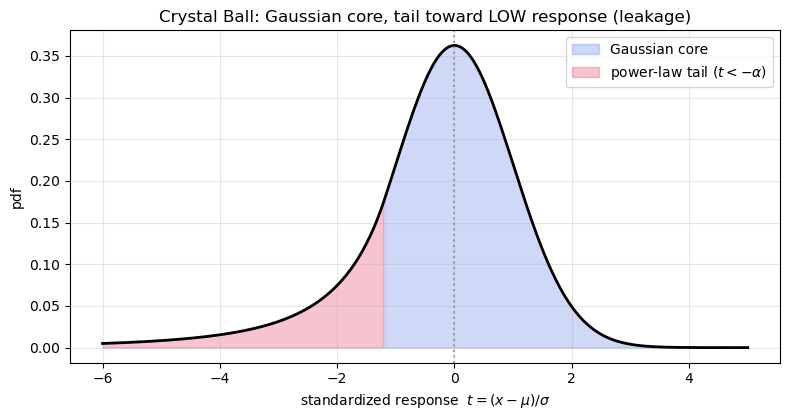

In [4]:
# fit_response() is imported above (analysis/decal_cbfit.py, shared with notebook 04): a binned
# single-sided Crystal-Ball fit that degrades gracefully CB -> Gaussian -> mean/RMS. Here we
# just draw the shape it fits.
# the shape: Gaussian core + low-side power-law tail
xx = np.linspace(-6, 5, 500); beta_d, m_d = 1.2, 4.0
yy = crystalball.pdf(xx, beta_d, m_d)
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.plot(xx, yy, color="k", lw=2)
ax.fill_between(xx, yy, where=(xx > -beta_d), color="royalblue", alpha=0.25, label="Gaussian core")
ax.fill_between(xx, yy, where=(xx <= -beta_d), color="crimson", alpha=0.25, label=r"power-law tail ($t<-\alpha$)")
ax.axvline(0, color="gray", ls=":", alpha=0.7)
ax.set_xlabel(r"standardized response  $t=(x-\mu)/\sigma$"); ax.set_ylabel("pdf")
ax.set_title(r"Crystal Ball: Gaussian core, tail toward LOW response (leakage)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 4. Load the fixed-energy runs

Each `.npz` in `MONO_DIR` is one mono-energetic beam: aligned per-event arrays of the four
readouts, `all_truth` (a spike at the beam energy), and a scalar `E_nominal`. We sort by
energy and confirm each run really is mono-energetic (`std(all_truth)` ≈ 0).

In [5]:
def load_per_energy(datadir):
    files = sorted(glob.glob(os.path.join(datadir, "*.npz")))
    if not files:
        raise FileNotFoundError("\n".join([
            f"No per-energy .npz in {datadir}.",
            "Generate fixed-energy beams (nb00, one CALOMAPS_GUN_ENERGY_GEV per energy), then run",
            "analysis/extract_readouts.py on each to write",
            "models/mono_<tag>/decal_mono_<tag>_E####GeV.npz (see that script's docstring for the",
            "exact loop), then set CALOMAPS_MONO_DIR."]))
    pts = []
    for f in files:
        d = np.load(f)
        E = float(d["E_nominal"]) if "E_nominal" in d.files else float(np.median(d["all_truth"]))
        obs = {name: np.asarray(d[KEYS[name]], float) for name in METHODS}
        pts.append({"E": E, "obs": obs, "n": int(np.size(d["all_truth"])),
                    "tstd": float(np.std(d["all_truth"]))})
    pts.sort(key=lambda t: t["E"])
    return pts

points = load_per_energy(MONO_DIR)
E_pts = np.array([p["E"] for p in points])
print(f"{len(points)} fixed-energy runs from {MONO_DIR}:")
for p in points:
    print(f"  E = {p['E']:6.1f} GeV   N = {p['n']:5d}   std(truth) = {p['tstd']:.3g} GeV")

9 fixed-energy runs from /nashome/m/murtazas/CALOMAPS-wt-pixelav-cms/models/mono_gamma:
  E =    1.0 GeV   N =  5000   std(truth) = 0 GeV
  E =    2.0 GeV   N =  5000   std(truth) = 0 GeV
  E =    5.0 GeV   N =  5000   std(truth) = 0 GeV
  E =   10.0 GeV   N =  5000   std(truth) = 0 GeV
  E =   20.0 GeV   N =  5000   std(truth) = 0 GeV
  E =   50.0 GeV   N =  5000   std(truth) = 0 GeV
  E =  100.0 GeV   N =  5000   std(truth) = 0 GeV
  E =  200.0 GeV   N =  5000   std(truth) = 0 GeV
  E =  400.0 GeV   N =  5000   std(truth) = 0 GeV


## 5. Do the fits describe the data?

Never quote a σ you have not looked at. Here is the Crystal-Ball fit overlaid on the response
histogram at **several fixed energies spanning the range** — check that the fitted function
tracks the data at each one: the Gaussian core on the peak, the power-law arm following the
low-side leakage tail (which grows with energy). If the fits look good here, the σ values that
feed every plot below are trustworthy. (Analog shown; set `SHOW_METHOD` for the digital readouts.)

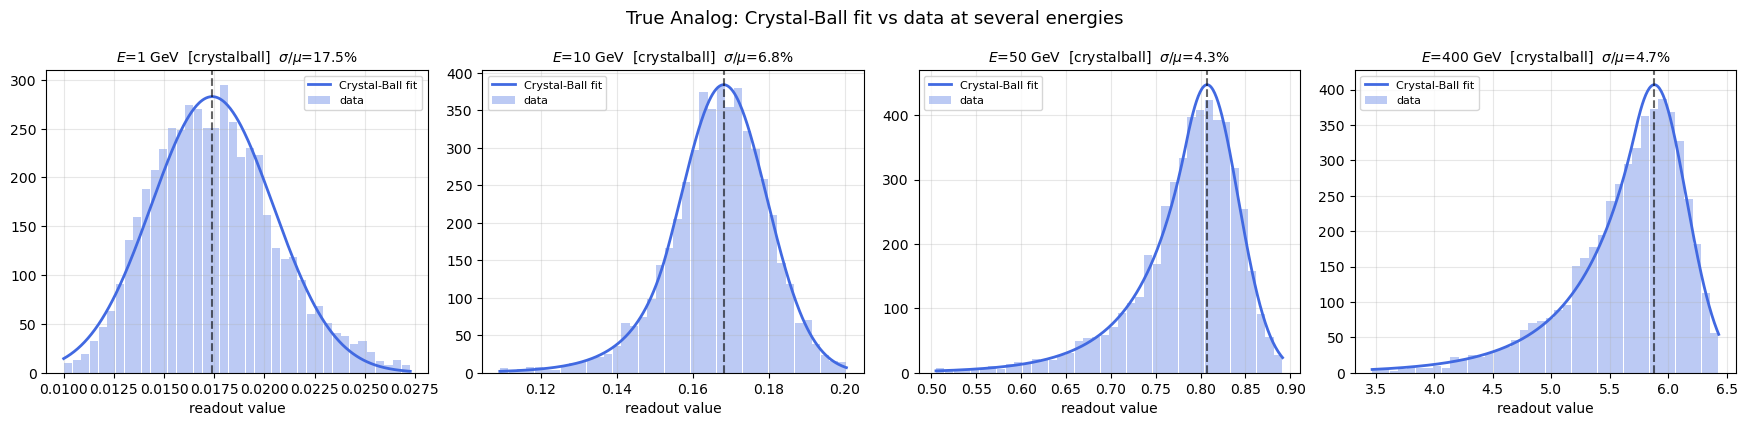

In [6]:
SHOW_METHOD = "Analog"
# ~4 energy points spread across the available range
_idx = sorted(set(np.linspace(0, len(points) - 1, 4).round().astype(int)))
show_pts = [points[i] for i in _idx]
fig, axes = plt.subplots(1, len(show_pts), figsize=(4.4 * len(show_pts), 4.3))
for ax, p in zip(np.atleast_1d(axes), show_pts):
    v = p["obs"][SHOW_METHOD]; r = fit_response(v)
    lo, hi = np.percentile(v, [0.3, 99.7])
    counts, edges = np.histogram(v, bins=40, range=(lo, hi))
    centers = 0.5 * (edges[:-1] + edges[1:]); bw = edges[1] - edges[0]
    ax.bar(centers, counts, width=bw * 0.95, color=COLORS[SHOW_METHOD], alpha=0.35, label="data")
    xx = np.linspace(lo, hi, 400)
    if r["model"] == "crystalball":
        ax.plot(xx, v.size * bw * crystalball.pdf(xx, r["beta"], r["m"], loc=r["mu"], scale=r["sigma"]),
                color=COLORS[SHOW_METHOD], lw=2, label="Crystal-Ball fit")
    elif r["model"] == "gaussian":
        ax.plot(xx, v.size * bw * norm.pdf(xx, loc=r["mu"], scale=r["sigma"]),
                color=COLORS[SHOW_METHOD], lw=2, ls="--", label="Gaussian fit")
    ax.axvline(r["mu"], color="k", ls="--", alpha=0.6)
    _som = 100 * r["sigma"] / r["mu"] if r["mu"] else float("nan")
    ax.set_title(rf"$E$={p['E']:.0f} GeV  [{r['model']}]  $\sigma/\mu$={_som:.1f}%", fontsize=10)
    ax.set_xlabel("readout value"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle(f"{LABELS[SHOW_METHOD]}: Crystal-Ball fit vs data at several energies", fontsize=13)
plt.tight_layout(); plt.show()

## 6. Fit every (readout, energy), and build the calibration

Loop the scan: for each readout at each energy, fit the response and record the peak $\mu$
(the **calibration** point) and the core width $\sigma$. The $\mu(E)$ curve is the **response
/ calibration curve** — the map from energy to readout. On log-log a linear readout is a
straight line; **flattening is saturation** (a binary pixel struck many times still counts
once). This curvature is the root cause of everything in the resolution plots that follow. The bend
of the digital readouts in the calibration plot below is what §7 inverts.

In [7]:
# --- fit every (readout, energy): record the calibration peak mu, core width sigma, its error ---
fit = {m: {"E": [], "mu": [], "sigma": [], "sigma_err": [], "raw": [], "model": []} for m in METHODS}
for p in points:
    for m in METHODS:
        r = fit_response(p["obs"][m])
        if r["ok"] and r["mu"] > 0:
            fit[m]["E"].append(p["E"]); fit[m]["mu"].append(r["mu"])
            fit[m]["sigma"].append(r["sigma"]); fit[m]["sigma_err"].append(r["sigma_err"])
            fit[m]["raw"].append(r["sigma"] / r["mu"]); fit[m]["model"].append(r["model"])
for m in METHODS:
    for k in ("E", "mu", "sigma", "sigma_err", "raw"):
        fit[m][k] = np.asarray(fit[m][k], float)

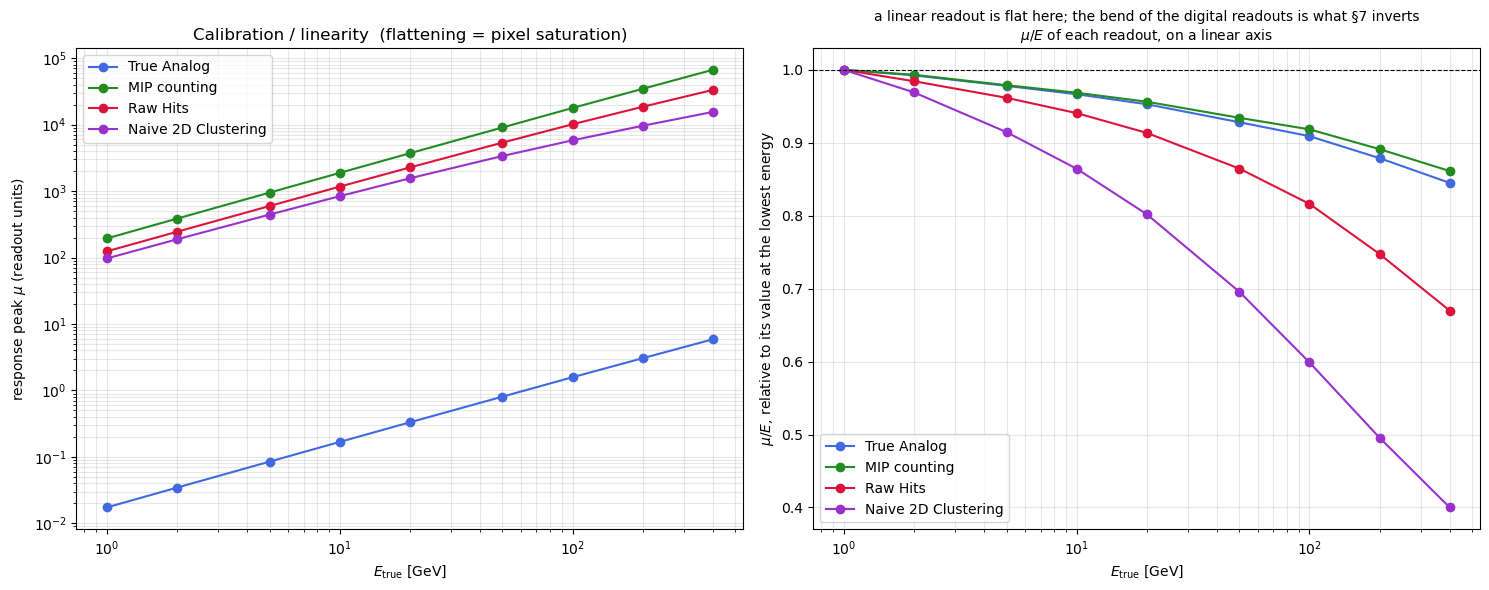

In [8]:
# the calibration / linearity plot; right: the same peaks divided by E, on a linear y axis
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 6))
for m in METHODS:
    ax.plot(fit[m]["E"], fit[m]["mu"], "o-", color=COLORS[m], label=LABELS[m])
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$E_{\rm true}$ [GeV]"); ax.set_ylabel(r"response peak $\mu$ (readout units)")
ax.set_title("Calibration / linearity  (flattening = pixel saturation)")
ax.legend(); ax.grid(alpha=0.3, which="both")
# mu / E of each readout, divided by its value at its lowest fitted energy (the readouts' units differ)
for m in METHODS:
    if fit[m]["E"].size == 0: continue
    _per_gev = fit[m]["mu"] / fit[m]["E"]
    ax2.plot(fit[m]["E"], _per_gev / _per_gev[0], "o-", color=COLORS[m], label=LABELS[m])
ax2.axhline(1.0, color="k", ls="--", lw=0.8)
ax2.set_xscale("log")
ax2.set_xlabel(r"$E_{\rm true}$ [GeV]"); ax2.set_ylabel(r"$\mu/E$, relative to its value at the lowest energy")
ax2.set_title("a linear readout is flat here; the bend of the digital readouts is what §7 inverts\n"
              r"$\mu/E$ of each readout, on a linear axis", fontsize=10)
ax2.legend(); ax2.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

## 7. From a readout width to an energy resolution: **invert the calibration**

A width $\sigma$ in *readout units* is not a resolution yet — we want it in **energy**. To
convert, we need the map from readout **back** to energy, i.e. the **inverse of the
calibration** $E_{\rm reco}=\mu^{-1}(\text{readout})$.

**The ML notebook (04) makes exactly the same move:**

| step | this notebook (conventional) | notebook 04 (ML) |
|---|---|---|
| forward model $E\to$ readout | the calibration $\mu(E)$, **measured** point-by-point | $\mu(E)$ as a smooth function, **learned** from a spectrum |
| reconstruct energy | invert the calibration curve | invert the learned $\mu(E)$ |
| resolution | width of the inverted $\mu\pm\sigma$ band | width of the inverted learned $\mu\pm\sigma$ band |

Same recipe — *build a forward response model, then invert it.* Ours is a monotonic curve
through the fixed-energy points; 04's is a network trained on the whole spectrum. Below we
build that inverse (a PCHIP interpolation: monotone and piecewise cubic, so the curve can be read backwards
without wiggles) and **show the inversion**: take the
readout band $\mu\pm\sigma$ at one energy and read it back onto the energy axis.


**The inversion, drawn.** A sketch: the same readout band read back to energy under a straight and a bending calibration; the inversion plot after it is the real case at 200 GeV, [192, 208] GeV for analog against [188, 212] GeV for clustering.

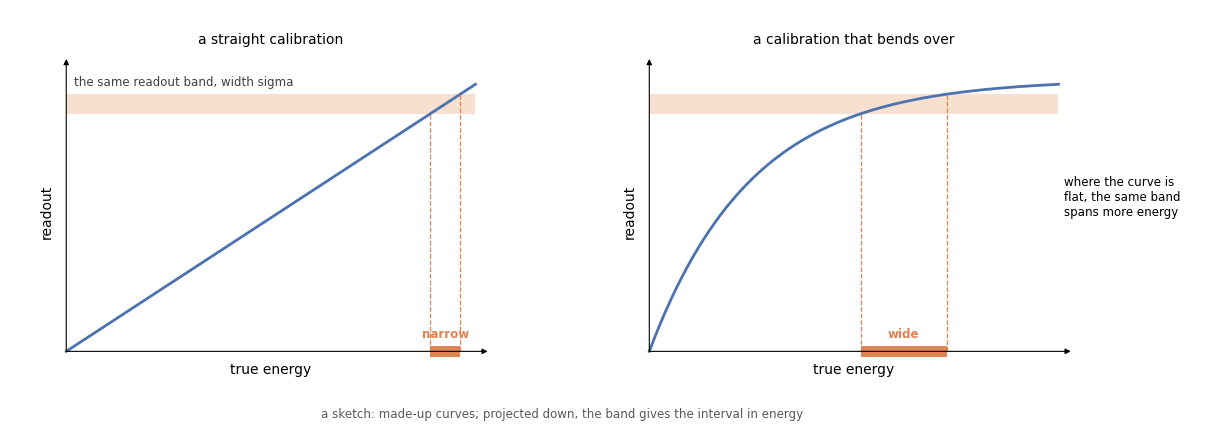

In [9]:
sketches.inversion()
plt.show()

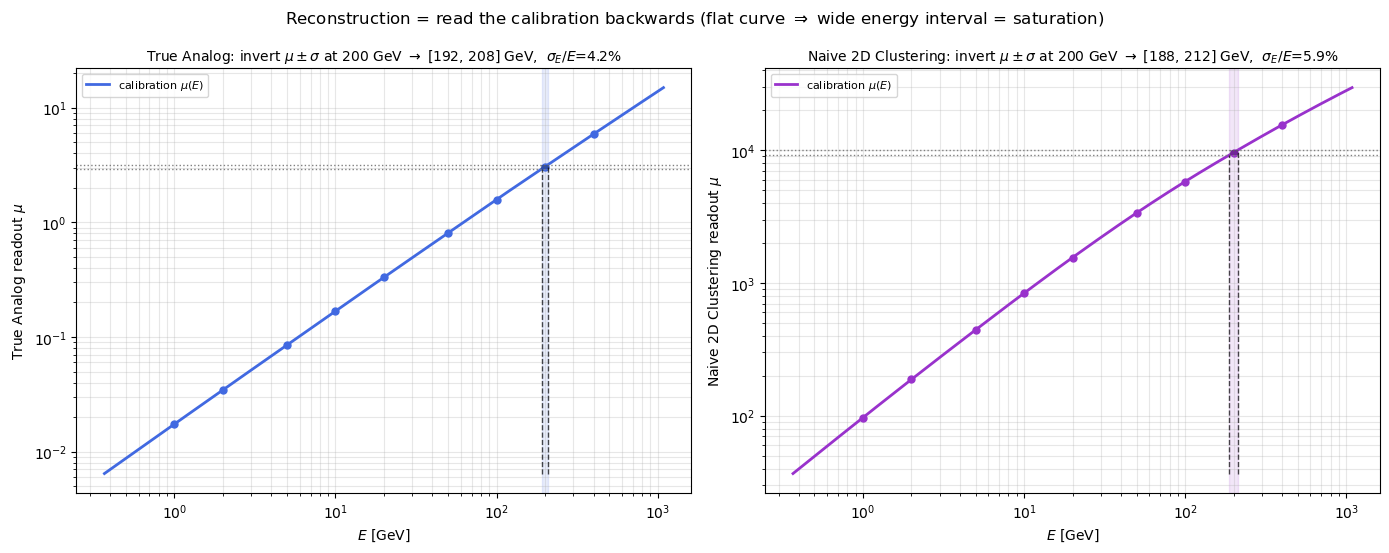

In [10]:
# build_calibration() is imported above (analysis/decal_cbfit.py, shared with notebook 04): it returns
# the forward calibration g(E), its inverse ginv(readout)->E (linear log-log extrapolation beyond
# the fitted range so an up-fluctuation is not silently clamped), and grids for plotting.
# SHOW the inversion: linear (Analog) vs saturating (Cluster) at a high energy
demoE = E_pts[np.argmin(np.abs(E_pts - 200))]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, m in zip(axes, ["Analog", "Cluster"]):
    E, mu, sig = fit[m]["E"], fit[m]["mu"], fit[m]["sigma"]
    if np.unique(E).size < 2:
        ax.set_title(f"{LABELS[m]}: need >= 2 energy points"); continue
    g, ginv, Eg, mug = build_calibration(E, mu)
    i = int(np.argmin(np.abs(E - demoE))); Ei, mi, si = E[i], mu[i], sig[i]
    Elo, Ehi = float(ginv(mi - si)), float(ginv(mi + si))
    ax.plot(Eg, mug, color=COLORS[m], lw=2, label=r"calibration $\mu(E)$")
    ax.plot(E, mu, "o", color=COLORS[m], ms=5)
    ax.axhline(mi + si, color="gray", ls=":", lw=1); ax.axhline(mi - si, color="gray", ls=":", lw=1)
    ax.plot([Ei, Ei], [mi - si, mi + si], color="k", lw=6, alpha=0.25, solid_capstyle="butt")
    for Ex, my in ((Elo, mi - si), (Ehi, mi + si)):
        ax.plot([Ex, Ex], [mug.min(), my], color="k", ls="--", lw=1, alpha=0.7)
    ax.axvspan(Elo, Ehi, color=COLORS[m], alpha=0.12)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$E$ [GeV]"); ax.set_ylabel(rf"{LABELS[m]} readout $\mu$")
    ax.set_title(rf"{LABELS[m]}: invert $\mu\pm\sigma$ at {Ei:.0f} GeV $\to$ "
                 rf"[{Elo:.0f}, {Ehi:.0f}] GeV,  $\sigma_E/E$={ (Ehi-Elo)/(2*Ei)*100:.1f}%", fontsize=10)
    ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
fig.suptitle(r"Reconstruction = read the calibration backwards "
             r"(flat curve $\Rightarrow$ wide energy interval = saturation)", fontsize=12)
plt.tight_layout(); plt.show()

For the **linear** analog readout the inversion barely changes anything —
$\sigma_E/E\approx\sigma/\mu$. For the **digital** readouts it is essential: where the
calibration flattens, a small readout band maps to a *large* energy band, so the true energy
resolution is far worse than the raw count width $\sigma/\mu$ suggests. Quoting $\sigma/\mu$
of the counts would **hide the saturation**. Below we compute both — the naive
$\sigma/\mu$ (dashed) and the honest, inverted $\sigma_E/E$ (solid).

> **The "slope correction," if you have seen it.** Linearizing the inversion gives
> $\sigma_E/E \approx (\sigma/\mu)\,/\,(\mathrm{d}\ln\mu/\mathrm{d}\ln E)$ — dividing the raw
> width by the local slope of the calibration. That is just the first-order Taylor expansion
> of what we do here exactly by inverting the curve.

In [11]:
# --- invert the calibration band mu +/- sigma -> energy interval -> sigma_E/E ---
for m in METHODS:
    E, mu, sig = fit[m]["E"], fit[m]["mu"], fit[m]["sigma"]
    if np.unique(E).size < 2:                       # too few points to invert
        fit[m]["res"] = np.full(np.shape(E), np.nan); continue
    g, ginv, Eg, mug = build_calibration(E, mu)
    fit[m]["res"] = (ginv(mu + sig) - ginv(mu - sig)) / (2.0 * E)   # honest sigma_E/E

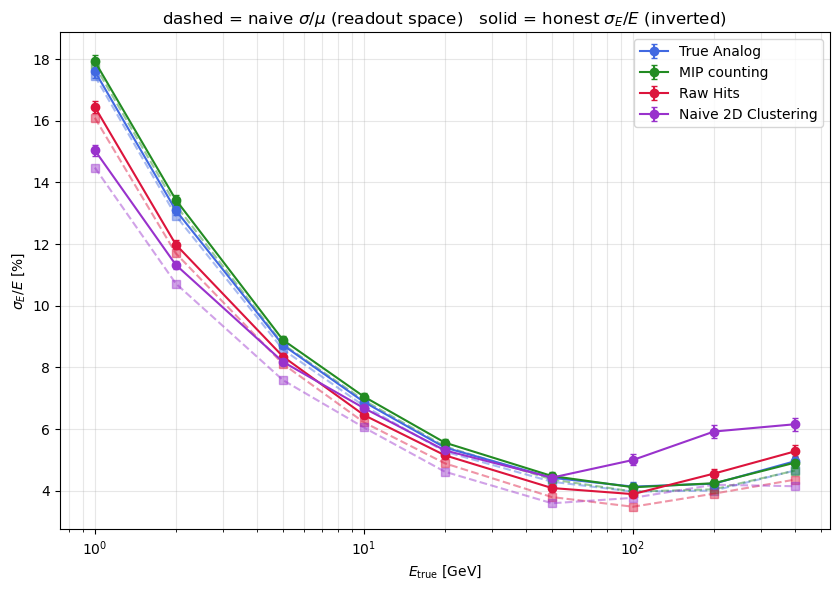

In [12]:
# propagate the fit-width uncertainty to sigma_E/E, then plot naive vs honest
for m in METHODS:
    rel = np.divide(fit[m]["sigma_err"], fit[m]["sigma"],
                    out=np.zeros_like(fit[m]["sigma"]), where=fit[m]["sigma"] > 0)
    fit[m]["res_err"] = fit[m]["res"] * rel        # sigma_E/E scales ~linearly with the width
fig, ax = plt.subplots(figsize=(8.5, 6))
for m in METHODS:
    ax.plot(fit[m]["E"], 100 * fit[m]["raw"], "s--", color=COLORS[m], alpha=0.45)
    ax.errorbar(fit[m]["E"], 100 * fit[m]["res"], yerr=100 * fit[m]["res_err"],
                fmt="o-", color=COLORS[m], capsize=2, label=LABELS[m])
ax.set_xscale("log"); ax.set_xlabel(r"$E_{\rm true}$ [GeV]"); ax.set_ylabel(r"$\sigma_E/E$ [%]")
ax.set_title(r"dashed = naive $\sigma/\mu$ (readout space)   solid = honest $\sigma_E/E$ (inverted)")
ax.legend(); ax.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

## 8. The money plot: $\sigma_E/E$ versus $1/\sqrt{E}$

If resolution were purely stochastic, $\sigma_E/E=a/\sqrt{E}$ would be a **straight line
through the origin** against $1/\sqrt{E}$. The standard calorimeter law is
$\sigma_E/E=a/\sqrt{E}\oplus b\oplus c/E$ (stochastic $\oplus$ constant $\oplus$ electronic
noise), but **this simulation has no electronics noise**, so we fit the two-term
$a/\sqrt{E}\oplus b$ — a free $c/E$ would only soak up low-$E$ fit scatter and get mislabelled
"noise". The fit is **weighted by the per-point uncertainties** from §7 (error bars below).
Expect the **analog** readout to track a near-straight line (stochastic-dominated). At this fine
100 µm pitch the **core** width of raw Hits stays close to analog across the whole range —
saturation is mild — so the clearest high-$E$ upturn is the **naive clustering** (its cluster
*count* merges in the dense core) and, for every digital readout, the *tail-inclusive* width (half of $P_{84}-P_{16}$, which keeps the tail) rather
than the Gaussian core (notebook 04 §7 separates the two). The fitted $a$ (in %·$\sqrt{\rm GeV}$) and $b$ (in %) print below; the top
axis reads back in GeV. In the plot below, see where each fit meets the vertical axis
($1/\sqrt{E}=0$, infinite energy): near 4%, not 0. That height is the constant term $b$.

In [13]:
# --- fit sigma_E/E = a/sqrt(E) (+) b  (quadrature; no c/E -- this sim has no noise) ---
def fit_stochastic(E, res, res_err=None):
    def model(E, a, b):
        return np.sqrt((a / np.sqrt(E))**2 + b**2)
    ok = np.isfinite(E) & np.isfinite(res) & (res > 0)
    if ok.sum() < 2: return None, model
    sig = None
    if res_err is not None:
        s = np.asarray(res_err, float)[ok]
        if np.all(np.isfinite(s)) and np.all(s > 0):
            sig = s                                   # weight by the per-point uncertainty
    try:
        p, _ = curve_fit(model, E[ok], res[ok], p0=[0.2, 0.02], sigma=sig,
                         absolute_sigma=sig is not None, bounds=([0, 0], [np.inf, np.inf]),
                         maxfev=40000)
        return p, model
    except Exception:
        return None, model

readout                a [%.sqrt(GeV)]     b [%]
True Analog                       17.3       4.0
MIP counting                      17.8       4.0
Raw Hits                          16.0       3.9
Naive 2D Clustering               14.4       4.8


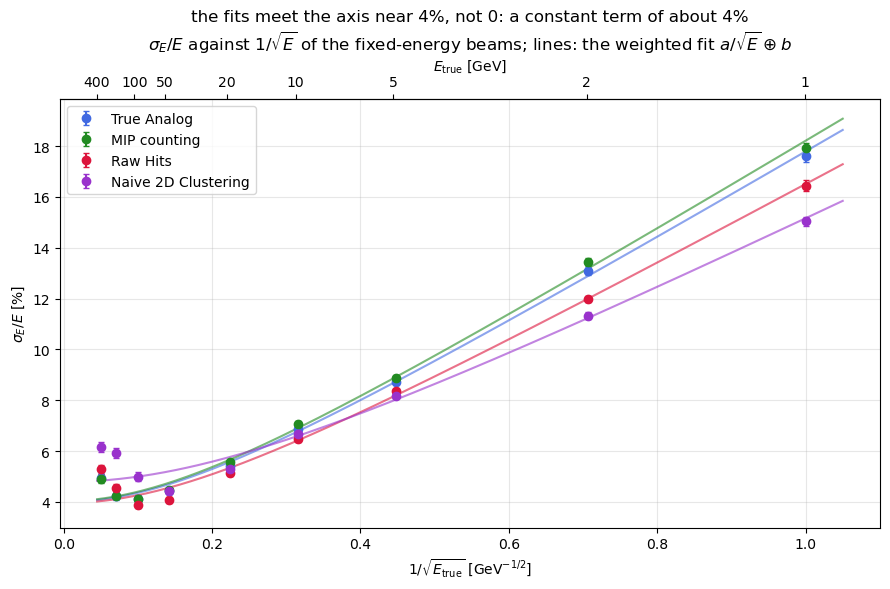

In [14]:
# the sigma_E/E vs 1/sqrt(E) money plot, with the weighted fit overlay + energy axis
fig, ax = plt.subplots(figsize=(9, 6))
print(f"{'readout':<20s}{'a [%.sqrt(GeV)]':>18s}{'b [%]':>10s}")
for m in METHODS:
    E, res = fit[m]["E"], fit[m]["res"]; x = 1.0 / np.sqrt(E)
    ax.errorbar(x, 100 * res, yerr=100 * fit[m]["res_err"], fmt="o", color=COLORS[m],
                capsize=2, label=LABELS[m])
    p, model = fit_stochastic(E, res, fit[m]["res_err"])
    if p is not None:
        xx = np.linspace(x.min() * 0.9, x.max() * 1.05, 200)
        ax.plot(xx, 100 * model(1.0 / xx**2, *p), "-", color=COLORS[m], alpha=0.6)
        print(f"{LABELS[m]:<20s}{100*p[0]:>18.1f}{100*p[1]:>10.1f}")
ax.set_xlabel(r"$1/\sqrt{E_{\rm true}}$ [GeV$^{-1/2}$]"); ax.set_ylabel(r"$\sigma_E/E$ [%]")
ax.set_title("the fits meet the axis near 4%, not 0: a constant term of about 4%\n"
             r"$\sigma_E/E$ against $1/\sqrt{E}$ of the fixed-energy beams; lines: the weighted fit $a/\sqrt{E}\oplus b$")
def _to_e(x):   return 1.0 / np.clip(np.asarray(x, float), 1e-6, None)**2
def _from_e(E): return 1.0 / np.sqrt(np.clip(np.asarray(E, float), 1e-6, None))
sec = ax.secondary_xaxis("top", functions=(_to_e, _from_e))
sec.set_xlabel(r"$E_{\rm true}$ [GeV]"); sec.set_xticks([400, 100, 50, 20, 10, 5, 2, 1])
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 9. Conventional vs ML resolution — when to use which

You now have the conventional measurement. Notebook
[04](04_resolution_ml_crystalball.ipynb) measures the **same quantity** a completely
different way; the contrast is worth previewing.

| | **Conventional (this notebook)** | **ML density ([nb04](04_resolution_ml_crystalball.ipynb))** |
|---|---|---|
| input data | dedicated **fixed-energy** runs (more simulation) | one **continuous spectrum** run (+ two low-energy anchor beams) |
| model | a Crystal-Ball fit per energy + a calibration curve | one network outputting the Crystal-Ball parameters vs energy |
| what "resolution" is | core σ of the response, **inverted** to energy | the identical core σ (plus a tail-inclusive width), inverted |
| compute | a few `curve_fit`s, seconds, no GPU | ensemble training on a GPU |
| transparency | every step readable by eye; **ground truth** | a fitted surrogate; harder to audit |
| energy coverage | only the energies you simulated (discrete) | the whole continuum at once |
| main risk | assumes a fit form; needs enough stats per point | needs spectrum coverage; extrapolates blindly outside it |

Neither is "better" — they answer the same question from opposite directions, which is
exactly why running both is valuable:

- **The two use the *same* core-width definition**, so across the full 1–400 GeV range the
  ML curve tracks this notebook's points across 1–400 GeV (04 §7–§8 overlay them directly), with a
  small residual constant-term offset quantified there. The ML fit is unbinned maximum likelihood where this notebook is a binned
  $\chi^2$, so a small constant-term difference remains: $b$ is 4.0, 4.0 and 3.9% here (§8)
  against 3.47, 3.45 and 3.50% in notebook 04 §8 for the three pixel readouts (clustering:
  4.8% against 4.88%) — a
  fit-method effect, quantified in 04 §8, not a physics disagreement.
- **Where both methods strain is physics, not error.** At very low energy the digital
  readouts are small-integer counts (discrete, non-Gaussian — the binned Crystal-Ball
  fit here still resolves a core where notebook 04's unbinned continuous density strains more); deep in
  saturation the calibration is nearly flat, so *any* inversion becomes sensitive — that
  sensitivity is the real message (the readout is running out of information), not a
  numerical artifact.

**Takeaways from the plots above:**

- **Analog** is the benchmark: linear calibration, near-straight $\sigma_E/E$ vs
  $1/\sqrt{E}$, small constant term — the "$1/\sqrt{E}$ is a straight line" intuition made real.
- **Digital readouts** (MIP → Hits → Cluster) trade the analog Landau tail for a
  **saturation** problem that grows with energy; the naive clustering saturates earliest. At
  **low** energy binary counting can actually *win* (it truncates the Landau tail: the rare large losses that give one pixel's
  deposit a long high side, notebook 01 §9).
- The **inversion** in §7 is what separates a naive "width of the count" from a real energy
  resolution — and it is the exact conventional counterpart of 04's ML reconstruction.

> **Extend it.** Re-run §0–§8 for `PARTICLE = "pi+"` and watch the method **strain**. This is
> an EM calorimeter (~25 $X_0$ deep but only ~1 nuclear interaction length — both budgets are
> measured from the geometry in notebook 01 §3b), so many pions punch
> through as minimum-ionizing or interact late: the response goes **bimodal** — a
> punch-through peak plus a shower tail — instead of a single Gaussian core, and a single-peak
> Crystal-Ball fit no longer captures "the resolution." That breakdown is the lesson — hadronic
> calorimetry needs a different detector (more $\lambda_I$) and a different analysis.

**Can one network, trained once on the continuous spectrum, give these core widths at every energy at once and agree with the points of this notebook?**
